In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

proc = '../data/processed'
targets = [2002, 2009, 2014, 2015, 2016]
ds = xr.open_dataset(f'{proc}/marathwada_monthly_025.nc')
w = np.cos(np.deg2rad(ds.lat))
pr = ds['pr'].weighted(w).mean(('lat', 'lon')).to_series()
monsoon = pr[pr.index.month.isin([6, 7, 8, 9])]
jjas = monsoon.groupby(monsoon.index.year).sum()
tab = pd.DataFrame({'jjas_mm': jjas,
                    'jjas_dep_pct': (jjas / jjas.mean() - 1) * 100,
                    'jjas_rank': jjas.rank().astype(int)})   # 1 = driest
print(tab.sort_values('jjas_rank').head(10).round(0))
print(tab.loc[targets].round(0))

      jjas_mm  jjas_dep_pct  jjas_rank
time                                  
2015    425.0         -37.0          1
2014    425.0         -37.0          2
1984    433.0         -36.0          3
1985    479.0         -29.0          4
2012    489.0         -28.0          5
1994    492.0         -27.0          6
1997    528.0         -22.0          7
2009    529.0         -22.0          8
2008    545.0         -20.0          9
1986    546.0         -19.0         10
      jjas_mm  jjas_dep_pct  jjas_rank
time                                  
2002    679.0           0.0         26
2009    529.0         -22.0          8
2014    425.0         -37.0          2
2015    425.0         -37.0          1
2016    854.0          26.0         36


In [2]:
reg = pd.read_csv('../outputs/tables/marathwada_indices_regional.csv', index_col=0, parse_dates=True)
names = {'SPI-12': 'spi_12', 'SPEI-12 Th': 'spei_th_12', 'SPEI-12 Hg': 'spei_hg_12'}
dec = reg[reg.index.month == 12].copy()
dec.index = dec.index.year
for label, c in names.items():
    tab[label] = dec[c]
    tab[label + ' rank'] = dec[c].rank().astype(int)      # 1 = driest
sep = reg[reg.index.month == 9].copy()
sep.index = sep.index.year
tab['SPI-3 Sep'] = sep['spi_3']
tab['SPEI-3 Sep Th'] = sep['spei_th_3']
tab['SPEI-3 Sep Hg'] = sep['spei_hg_3']
print(tab.loc[targets].round(2).T)

time               2002    2009    2014    2015    2016
jjas_mm          679.29  529.38  425.26  424.65  854.33
jjas_dep_pct       0.31  -21.83  -37.20  -37.29   26.16
jjas_rank         26.00    8.00    2.00    1.00   36.00
SPI-12            -0.25   -0.52   -1.23   -1.51    0.94
SPI-12 rank       20.00   15.00    4.00    1.00   35.00
SPEI-12 Th        -0.60   -1.52   -1.33   -2.10    0.27
SPEI-12 Th rank   12.00    2.00    5.00    1.00   26.00
SPEI-12 Hg        -0.24   -0.79   -1.25   -1.70    0.80
SPEI-12 Hg rank   21.00   11.00    5.00    1.00   33.00
SPI-3 Sep         -0.59   -0.46   -0.94   -1.72    0.99
SPEI-3 Sep Th     -0.56   -0.70   -1.13   -2.44    1.07
SPEI-3 Sep Hg     -0.55   -0.50   -1.04   -2.07    1.09


In [3]:
flag = dec[list(names.values())] <= -1
flag.columns = list(names)
print(flag.loc[targets].astype(int))
for n in names:
    other = [y for y in flag.index[flag[n]] if y not in targets]
    print(n, 'flags', int(flag[n].sum()), 'Decembers; flagged outside the target list:', other)

      SPI-12  SPEI-12 Th  SPEI-12 Hg
time                                
2002       0           0           0
2009       0           1           0
2014       1           1           1
2015       1           1           1
2016       0           0           0
SPI-12 flags 10 Decembers; flagged outside the target list: [1984, 1985, 1986, 1991, 1994, 2011, 2012, 2018]
SPEI-12 Th flags 7 Decembers; flagged outside the target list: [1984, 2003, 2012, 2018]
SPEI-12 Hg flags 9 Decembers; flagged outside the target list: [1984, 1985, 1986, 1991, 2011, 2012, 2018]


In [4]:
ev = pd.read_csv('../outputs/tables/regional_drought_events.csv', parse_dates=['start', 'end'])
print(ev.columns.tolist())
for a, b in [('2001-01-01', '2003-12-31'), ('2008-01-01', '2010-12-31'), ('2013-01-01', '2017-12-31')]:
    print(a[:4], 'to', b[:4])
    print(ev[(ev.end >= a) & (ev.start <= b)].round(2).to_string(index=False))

['index', 'scale', 'start', 'end', 'duration', 'severity', 'intensity', 'peak']
2001 to 2003
  index  scale      start        end  duration  severity  intensity  peak
    spi      3 2001-07-01 2001-07-01         1      1.12       1.12 -1.12
    spi      3 2003-11-01 2003-12-01         2      2.45       1.23 -1.28
    spi     12 2001-07-01 2001-08-01         2      2.31       1.16 -1.18
spei_th      3 2002-04-01 2002-04-01         1      1.05       1.05 -1.05
spei_th      3 2002-12-01 2003-04-01         5      5.99       1.20 -1.60
spei_th      3 2003-11-01 2003-12-01         2      2.22       1.11 -1.17
spei_th     12 2003-06-01 2003-06-01         1      1.22       1.22 -1.22
spei_th     12 2003-10-01 2003-12-01         3      3.14       1.05 -1.10
spei_hg      3 2000-11-01 2001-02-01         4      5.20       1.30 -1.72
spei_hg      3 2002-12-01 2003-01-01         2      2.22       1.11 -1.12
spei_hg      3 2003-11-01 2003-12-01         2      2.25       1.13 -1.19
spei_hg     12 2001

C:\Users\DELL\AppData\Local\Temp\ipykernel_24292\1366886001.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(ev[(ev.end >= a) & (ev.start <= b)].round(2).to_string(index=False))
C:\Users\DELL\AppData\Local\Temp\ipykernel_24292\1366886001.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(ev[(ev.end >= a) & (ev.start <= b)].round(2).to_string(index=False))
C:\Users\DELL\AppData\Local\Temp\ipykernel_24292\1366886001.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(ev[(ev.end >= a) & (ev.start <= b)].round(2).to_string(index=False))


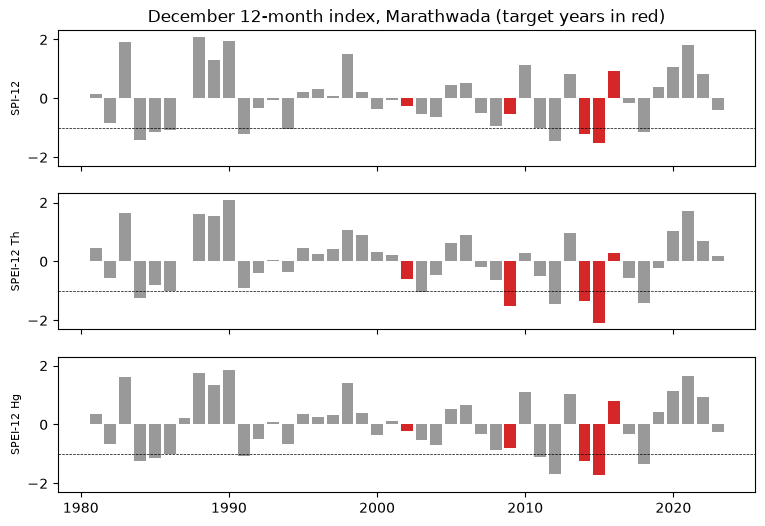

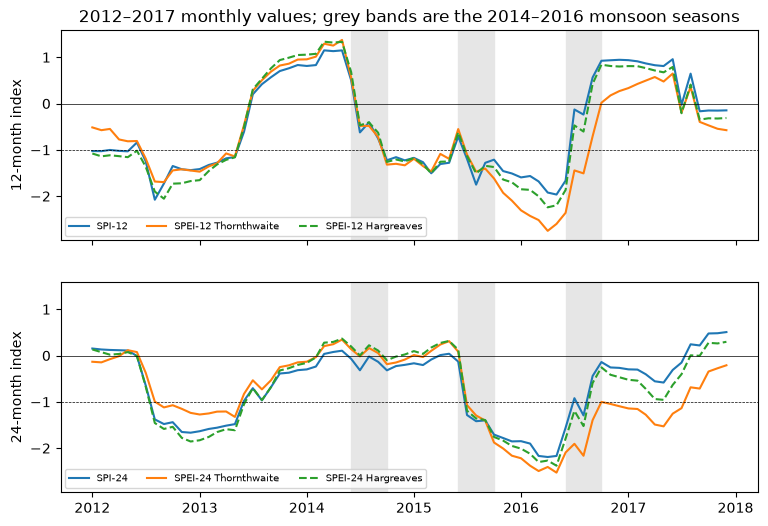

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, (label, c) in zip(axes, names.items()):
    s = dec[c]
    ax.bar(s.index, s, color=['tab:red' if y in targets else '0.6' for y in s.index])
    ax.axhline(-1, color='k', lw=0.5, ls='--')
    ax.set_ylabel(label, fontsize=8)
axes[0].set_title('December 12-month index, Marathwada (target years in red)')
fig.savefig('../outputs/figures/fig13_validation_december.png', dpi=300, bbox_inches='tight')

win = reg.loc['2012-01':'2017-12']
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, k in zip(axes, [12, 24]):
    ax.plot(win.index, win[f'spi_{k}'], label=f'SPI-{k}')
    ax.plot(win.index, win[f'spei_th_{k}'], label=f'SPEI-{k} Thornthwaite')
    ax.plot(win.index, win[f'spei_hg_{k}'], '--', label=f'SPEI-{k} Hargreaves')
    for y in (2014, 2015, 2016):
        ax.axvspan(pd.Timestamp(f'{y}-06-01'), pd.Timestamp(f'{y}-09-30'), color='0.9', zorder=0)
    ax.axhline(-1, color='k', lw=0.5, ls='--')
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylabel(f'{k}-month index')
    ax.legend(fontsize=7, ncol=3, loc='lower left')
axes[0].set_title('2012–2017 monthly values; grey bands are the 2014–2016 monsoon seasons')
fig.savefig('../outputs/figures/fig14_validation_2012_2017.png', dpi=300, bbox_inches='tight')

       spi  spei_th  spei_hg
time                        
2002  11.0     22.0     12.0
2009  16.0     54.0     32.0
2014  49.0     66.0     55.0
2015  64.0     86.0     68.0
2016   0.0      3.0      0.0


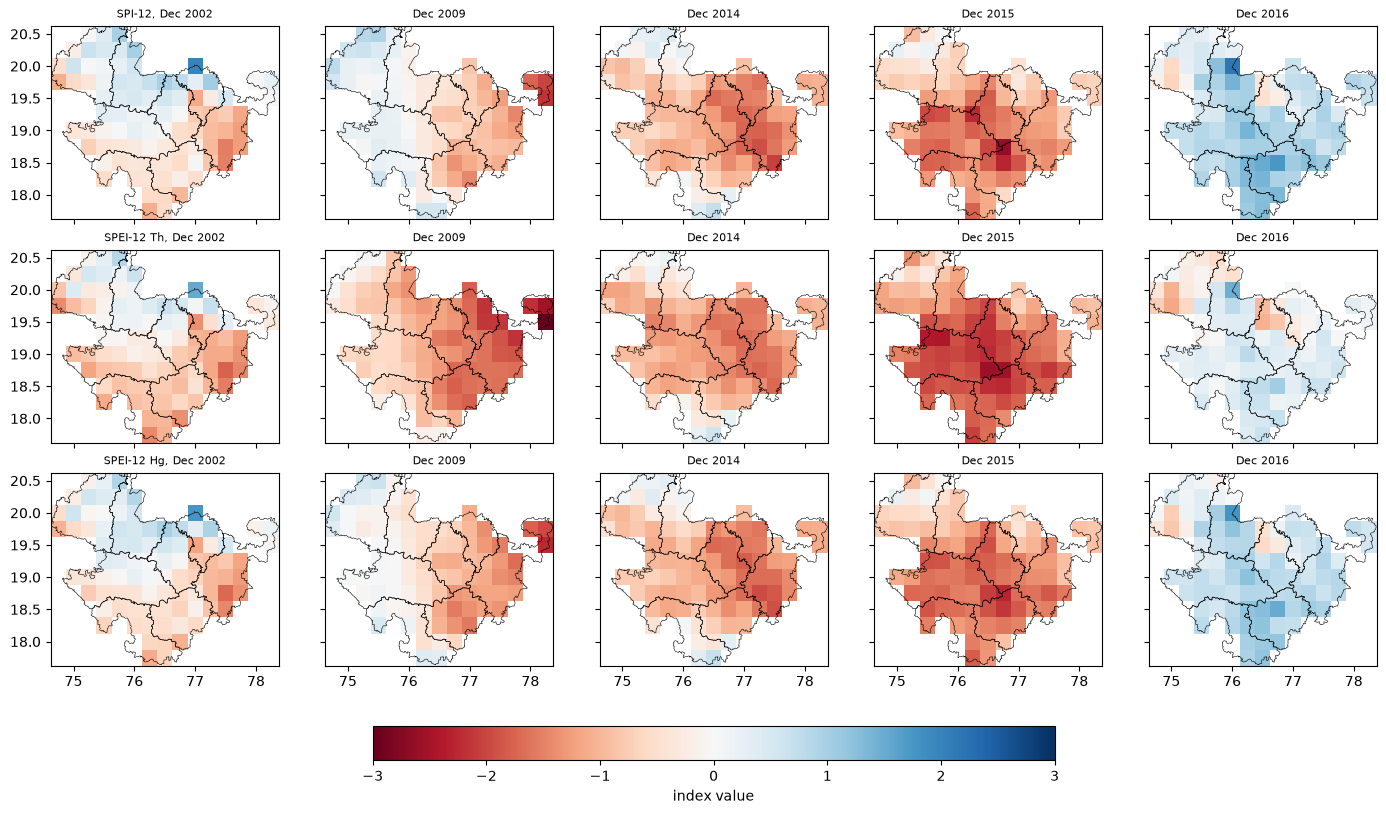

In [6]:
import geopandas as gpd
idx = xr.open_dataset(f'{proc}/marathwada_indices_025.nc')
inside = ds['pr'].notnull().any('time')
z12 = idx.sel(scale=12, drop=True)
zd = z12.isel(time=np.flatnonzero(z12.time.dt.month.values == 12))
frac = ((zd <= -1) & inside).sum(('lat', 'lon')) / int(inside.sum())
frac_tab = frac.to_dataframe()
frac_tab.index = frac_tab.index.year
print((frac_tab.loc[targets] * 100).round(0))

districts = gpd.read_file('../data/shapefiles/marathwada_districts.gpkg')
titles = {'spi': 'SPI-12', 'spei_th': 'SPEI-12 Th', 'spei_hg': 'SPEI-12 Hg'}
fig, axes = plt.subplots(3, 5, figsize=(14, 8), sharex=True, sharey=True, layout='constrained')
for i, (v, t) in enumerate(titles.items()):
    for j, y in enumerate(targets):
        ax = axes[i, j]
        im = zd[v].sel(time=f'{y}-12-01').plot(ax=ax, vmin=-3, vmax=3, cmap='RdBu', add_colorbar=False)
        districts.boundary.plot(ax=ax, color='k', lw=0.4)
        ax.set_title(f'{t}, Dec {y}' if j == 0 else f'Dec {y}', fontsize=8)
        ax.set_xlabel('')
        ax.set_ylabel('')
fig.colorbar(im, ax=axes, orientation='horizontal', shrink=0.5, label='index value')
fig.savefig('../outputs/figures/fig15_validation_maps.png', dpi=300)

In [7]:
print(reg.loc['2002-06':'2002-09', ['spi_1', 'spi_3']].round(2))   # was there a July 2002 dry spell?
pet = pd.read_csv('../outputs/tables/marathwada_pet_regional.csv', index_col=0, parse_dates=True)
ann = pet.resample('YS').sum()
print(((ann - ann.mean()) / ann.std()).loc['2008':'2010', ['pr', 'pet_th', 'pet_hg']].round(2))   # was 2009 a high-PET year?

            spi_1  spi_3
time                    
2002-06-01   1.51   1.41
2002-07-01  -1.81  -0.20
2002-08-01   0.84   0.37
2002-09-01  -0.23  -0.59
              pr  pet_th  pet_hg
time                            
2008-01-01 -0.91   -0.25    0.10
2009-01-01 -0.55    2.11    1.84
2010-01-01  1.12    2.10    0.15


In [8]:
   tab.round(3).to_csv('../outputs/tables/validation_all_years.csv')
   tab.loc[targets].round(3).to_csv('../outputs/tables/validation_target_years.csv')
   frac_tab.round(3).to_csv('../outputs/tables/validation_cell_fraction.csv')